<a href="https://colab.research.google.com/github/anthony-yt/deepwater-image-segmentation-classical-quantum/blob/feat%2Fscale-augmentation/notebooks/1_2_scale_invariance_augmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q "albumentations==2.0.8"

In [2]:
import hashlib
import os
import re
import sys
from pathlib import Path

import albumentations as A
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/Under_Water_Dataset")
else:
    DRIVE_ROOT = Path(os.environ.get("DW_DATA_ROOT", "Under_Water_Dataset")).resolve()

PROCESSED_DIR = DRIVE_ROOT / "Dataset_Processed"
FRAMES_DIR = PROCESSED_DIR / "Frames_CLAHE"
MASK_DIR_CANDIDATES = [PROCESSED_DIR / "Test_Set_Curado"]

OUT_SIZE = 512
SCALE_RANGE = (0.3, 1.5)
ZOOM_IN_AREA_RANGE = (0.3, 1.0)
LADDER_SCALES = (0.3, 0.5, 0.75, 1.0, 1.25, 1.5)
SAMPLES_PER_FRAME = 100
SEED = 42

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK_SOFT, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"

print("albumentations", A.__version__, "| OpenCV", cv2.__version__)

Mounted at /content/drive
albumentations 2.0.8 | OpenCV 5.0.0


## Why not the literal `RandomResizedCrop(scale=(0.3, 1.5))`

In [3]:
try:
    A.RandomResizedCrop(size=(OUT_SIZE, OUT_SIZE), scale=(0.3, 1.5))
except ValueError as error:
    reason = next((line.strip() for line in str(error).splitlines() if "must be" in line), str(error))
    print(f"albumentations {A.__version__} rejects scale=(0.3, 1.5):")
    print("  ", reason)

albumentations 2.0.8 rejects scale=(0.3, 1.5):
   Value error, All values in (0.3, 1.5) must be >= 0 and <= 1 [type=value_error, input_value=(0.3, 1.5), input_type=tuple]


## Transforms

In [4]:
IGNORE_INDEX = 255  # label of padded pixels, to be skipped by the loss


def zoom_in_out_transforms(out_size: int = 512, scale_range: tuple = (0.3, 1.5),
                           mask_fill: int = IGNORE_INDEX, image_fill: int = 0,
                           pad_position: str = "random") -> list:
    """Resize to out_size, rescale by s ~ U(scale_range), pad if s < 1, random-crop to out_size."""
    low, high = scale_range
    if not 0 < low <= high:
        raise ValueError(f"scale_range must satisfy 0 < low <= high, got {scale_range}")
    return [
        A.Resize(out_size, out_size, interpolation=cv2.INTER_AREA),
        A.RandomScale(scale_limit=(low - 1.0, high - 1.0), interpolation=cv2.INTER_LINEAR,
                      area_for_downscale="image", p=1.0),
        A.PadIfNeeded(min_height=out_size, min_width=out_size, position=pad_position,
                      border_mode=cv2.BORDER_CONSTANT, fill=image_fill, fill_mask=mask_fill),
        A.RandomCrop(height=out_size, width=out_size),
    ]


def zoom_in_only_transforms(out_size: int = 512, area_range: tuple = (0.3, 1.0)) -> list:
    """RandomResizedCrop: keeps a fraction of the frame area, so it can only zoom in."""
    low, high = area_range
    if not 0 < low <= high <= 1:
        raise ValueError(f"area_range must satisfy 0 < low <= high <= 1, got {area_range}")
    return [
        A.Resize(out_size, out_size, interpolation=cv2.INTER_AREA),
        A.RandomResizedCrop(size=(out_size, out_size), scale=(low, high), ratio=(1.0, 1.0),
                            interpolation=cv2.INTER_LINEAR, p=1.0),
    ]


def fixed_scale_transforms(scale: float, out_size: int = 512, mask_fill: int = IGNORE_INDEX,
                           image_fill: int = 0) -> list:
    """Centred, deterministic version of zoom_in_out_transforms at one scale."""
    if scale <= 0:
        raise ValueError(f"scale must be positive, got {scale}")
    return [
        A.Resize(out_size, out_size, interpolation=cv2.INTER_AREA),
        A.RandomScale(scale_limit=(scale - 1.0, scale - 1.0), interpolation=cv2.INTER_LINEAR,
                      area_for_downscale="image", p=1.0),
        A.PadIfNeeded(min_height=out_size, min_width=out_size, position="center",
                      border_mode=cv2.BORDER_CONSTANT, fill=image_fill, fill_mask=mask_fill),
        A.CenterCrop(height=out_size, width=out_size),
    ]

## Frames and masks

In [5]:
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

def frame_key(path) -> str:
    stem = re.sub(r"\s*\(\d+\)$", "", Path(path).stem)
    return re.sub(r"_mask$", "", stem, flags=re.IGNORECASE)

def index_dir(directory: Path) -> dict:
    index = {}
    if directory is None or not directory.is_dir():
        return index
    for path in sorted(directory.iterdir()):
        if path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue
        key = frame_key(path)
        if key not in index or path.stem.lower().endswith("_mask"):
            index[key] = path
    return index

def read_rgb(path) -> np.ndarray:
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Unreadable image: {path}")
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

def read_mask(path) -> np.ndarray:
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_UNCHANGED)
    if image is None:
        raise ValueError(f"Unreadable mask: {path}")
    if image.dtype == np.uint16:
        image = (image >> 8).astype(np.uint8)
    if image.ndim == 3:
        image = image[..., :3].max(axis=2)
    return (image.astype(bool) if image.max() <= 1 else image > 127).astype(np.uint8)

def video_of(frame_id: str) -> str:
    return frame_id.split("_frame_")[0]

frame_files = index_dir(FRAMES_DIR)
if not frame_files:
    raise FileNotFoundError(f"No frames found in {FRAMES_DIR}")
MASK_DIR = next((d for d in MASK_DIR_CANDIDATES if index_dir(d)), None)
mask_files = index_dir(MASK_DIR)
labelled = sorted(set(frame_files) & set(mask_files))

print(f"Frames: {len(frame_files)} in {FRAMES_DIR}")
display(pd.Series([video_of(f) for f in frame_files]).value_counts().sort_index().rename("frames").to_frame())
print(f"Masks : {len(labelled)} labelled frames from {MASK_DIR}")

def load_pair(frame_id: str) -> tuple:
    image = read_rgb(frame_files[frame_id])
    mask = read_mask(mask_files[frame_id]) if frame_id in mask_files else None
    if mask is not None and mask.shape != image.shape[:2]:
        mask = cv2.resize(mask, (image.shape[1], image.shape[0]), interpolation=cv2.INTER_NEAREST)
    return image, mask

Frames: 249 in /content/drive/MyDrive/Under_Water_Dataset/Dataset_Processed/Frames_CLAHE


,frames
DeepWater-Video1,22
DeepWater-Video2,23
DeepWater-Video3,49
DeepWater-Video4,50
DeepWater-Video5,71
DeepWater-Video6,24
DeepWater-Video7,10


Masks : 20 labelled frames from /content/drive/MyDrive/Under_Water_Dataset/Dataset_Processed/Test_Set_Curado


In [6]:
def apply(transforms: list, image: np.ndarray, mask=None, seed=None) -> dict:
    compose = A.Compose(transforms, seed=seed, save_applied_params=True)
    return compose(image=image) if mask is None else compose(image=image, mask=mask)

def applied_scale(output: dict) -> float:
    for name, params in output["applied_transforms"]:
        if name == "RandomScale":
            return float(params["scale"])
        if name == "RandomResizedCrop":
            x_min, y_min, x_max, y_max = params["crop_coords"]
            return float(np.sqrt(OUT_SIZE * OUT_SIZE / ((x_max - x_min) * (y_max - y_min))))
    return 1.0

def frame_seed(frame_id: str, salt: str = "") -> int:
    return int(hashlib.sha256(f"{SEED}:{salt}:{frame_id}".encode()).hexdigest()[:8], 16)

def outline(image: np.ndarray, mask) -> np.ndarray:
    canvas = image.copy()
    if mask is not None:
        contours, _ = cv2.findContours((mask == 1).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(canvas, contours, -1, (255, 255, 255), 5, cv2.LINE_AA)
        cv2.drawContours(canvas, contours, -1, (235, 104, 52), 2, cv2.LINE_AA)
    return canvas

def show(ax, image, title: str) -> None:
    ax.imshow(image)
    ax.set_title(title, fontsize=9, color=INK_SOFT)
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_color(GRID)

## What each end of the range looks like

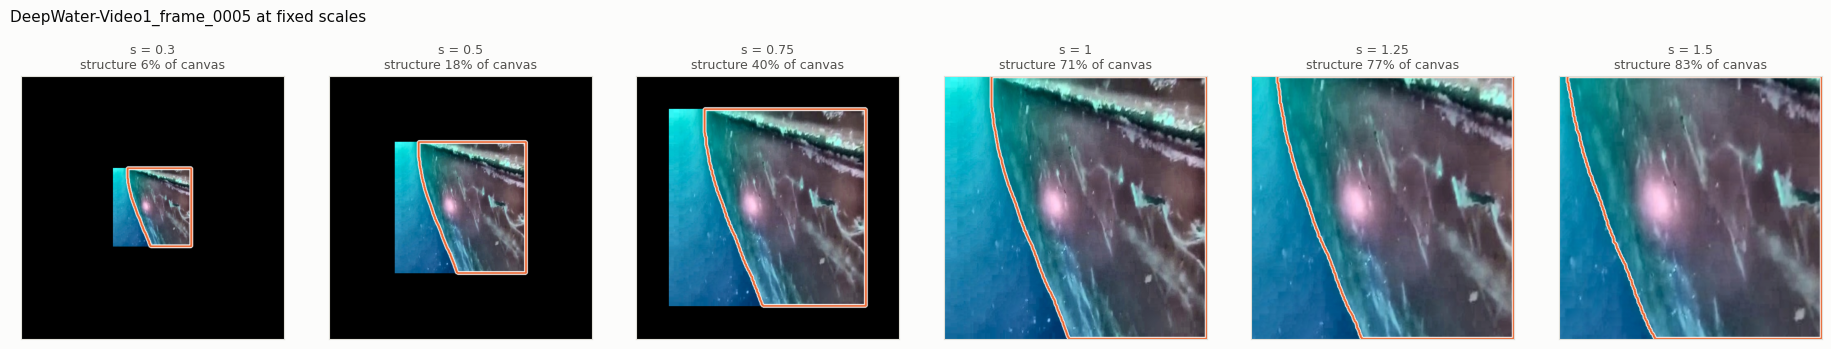

In [7]:
if labelled:
    structure_share = pd.Series({fid: float(load_pair(fid)[1].mean()) for fid in labelled}).sort_values()
    ladder_frame = structure_share.index[len(structure_share) // 2]   # the median frame
else:
    ladder_frame = sorted(frame_files)[0]

image, mask = load_pair(ladder_frame)
fig, axes = plt.subplots(1, len(LADDER_SCALES), figsize=(3.1 * len(LADDER_SCALES), 3.5), facecolor=SURFACE)
for ax, scale in zip(axes, LADDER_SCALES):
    out = apply(fixed_scale_transforms(scale, OUT_SIZE), image, mask)
    label = f"s = {scale:g}"
    if mask is not None:
        label += f"\nstructure {np.mean(out['mask'] == 1):.0%} of canvas"
    show(ax, outline(out["image"], out.get("mask")), label)
fig.suptitle(f"{ladder_frame} at fixed scales", x=0.01, y=0.985, ha="left", fontsize=11, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

## Before and after on representative frames

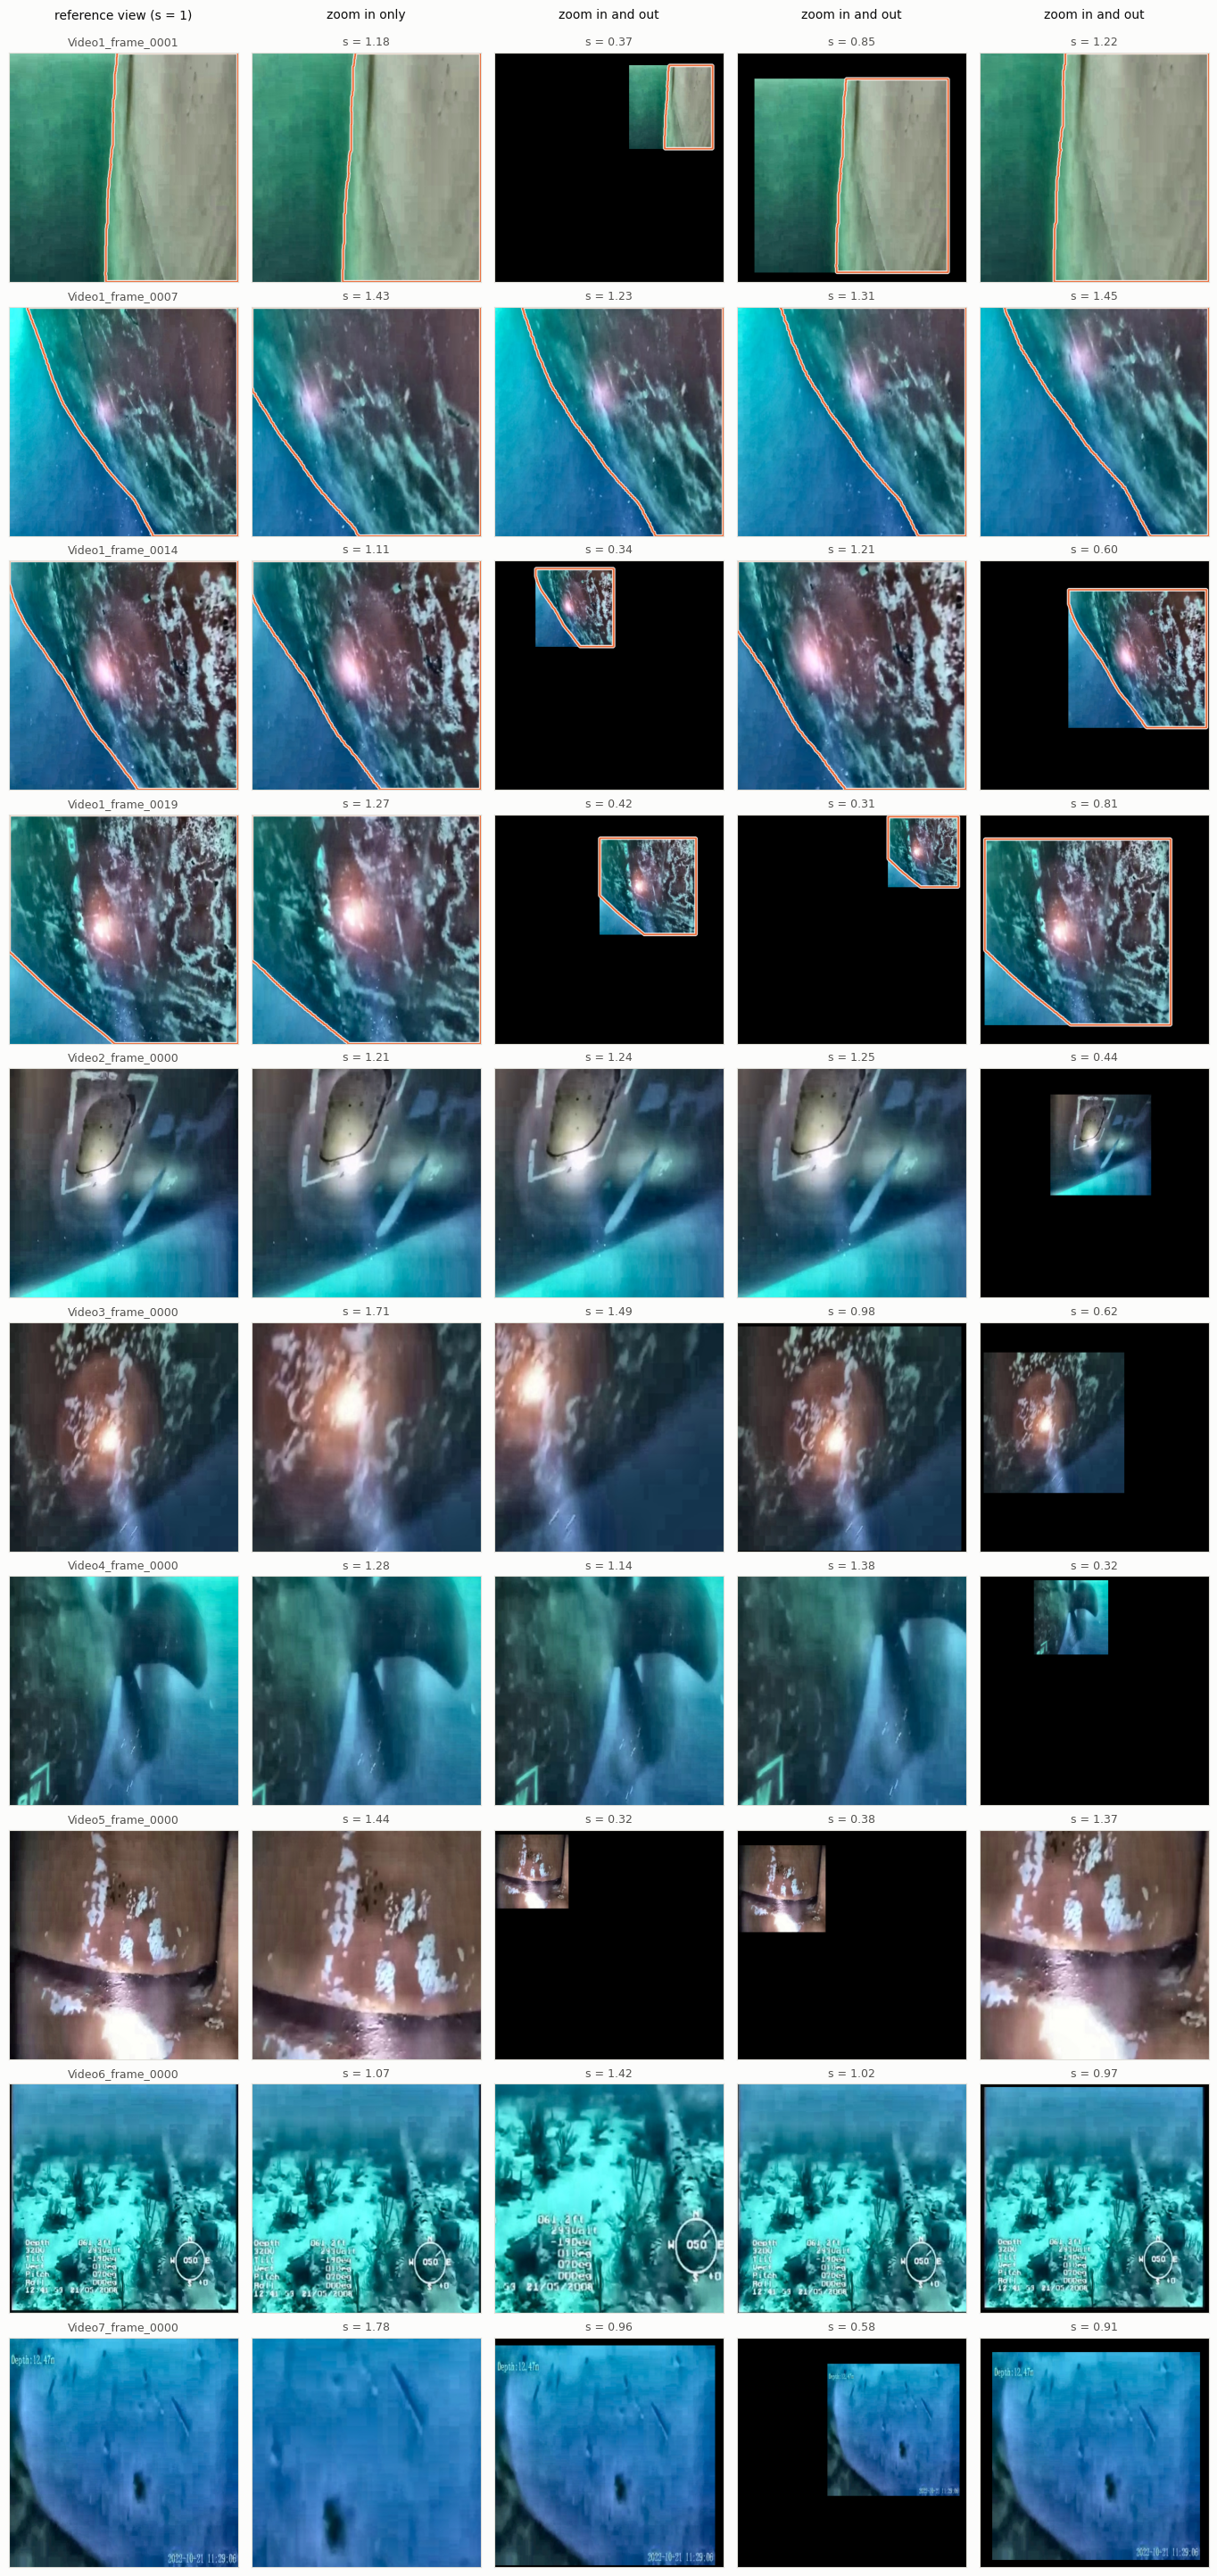

In [8]:
PANEL_FRAMES = None   # e.g. ["DeepWater-Video1_frame_0003", "DeepWater-Video3_frame_0010"]
N_RANDOM_COLUMNS = 3

def pick_panel_frames(n_labelled: int = 4, limit: int = 10) -> list:
    picks = []
    if labelled:
        positions = np.linspace(0, len(structure_share) - 1, min(n_labelled, len(structure_share))).round().astype(int)
        picks += [structure_share.index[i] for i in dict.fromkeys(positions)]
    labelled_videos = {video_of(frame_id) for frame_id in labelled}
    other_videos = {}
    for frame_id in sorted(frame_files):
        if video_of(frame_id) not in labelled_videos:
            other_videos.setdefault(video_of(frame_id), []).append(frame_id)
    per_video = 2 if len(other_videos) <= 3 else 1
    for video, frame_ids in sorted(other_videos.items()):
        positions = np.linspace(0, len(frame_ids) - 1, min(per_video, len(frame_ids))).round().astype(int)
        picks += [frame_ids[i] for i in dict.fromkeys(positions)]
    return picks[:limit]

panel_frames = PANEL_FRAMES or pick_panel_frames()
columns = ["reference view (s = 1)", "zoom in only"] + ["zoom in and out"] * N_RANDOM_COLUMNS
fig, axes = plt.subplots(len(panel_frames), len(columns), figsize=(2.75 * len(columns), 2.95 * len(panel_frames)),
                         facecolor=SURFACE)
axes = np.atleast_2d(axes)
for row, frame_id in enumerate(panel_frames):
    image, mask = load_pair(frame_id)
    reference = apply(fixed_scale_transforms(1.0, OUT_SIZE), image, mask)
    show(axes[row, 0], outline(reference["image"], reference.get("mask")), frame_id.replace("DeepWater-", ""))
    zoom_in = apply(zoom_in_only_transforms(OUT_SIZE, ZOOM_IN_AREA_RANGE), image, mask, seed=frame_seed(frame_id, "in"))
    show(axes[row, 1], outline(zoom_in["image"], zoom_in.get("mask")), f"s = {applied_scale(zoom_in):.2f}")
    for k in range(N_RANDOM_COLUMNS):
        sample = apply(zoom_in_out_transforms(OUT_SIZE, SCALE_RANGE), image, mask, seed=frame_seed(frame_id, f"panel{k}"))
        show(axes[row, 2 + k], outline(sample["image"], sample.get("mask")), f"s = {applied_scale(sample):.2f}")
for col, title in enumerate(columns):
    axes[0, col].annotate(title, xy=(0.5, 1.15), xycoords="axes fraction", ha="center", fontsize=10, color=INK)
fig.tight_layout(rect=(0, 0, 1, 1 - 0.22 / len(panel_frames)))
plt.show()

## Does it change the apparent distance?

In [9]:
def sample_variant(transforms: list, label: str) -> pd.DataFrame:
    rows = []
    for frame_id in labelled:
        image, mask = load_pair(frame_id)
        compose = A.Compose(transforms, seed=frame_seed(frame_id, label), save_applied_params=True)
        for _ in range(SAMPLES_PER_FRAME):
            out = compose(image=image, mask=mask)
            valid = out["mask"] != IGNORE_INDEX
            rows.append({
                "variant": label, "frame": frame_id, "scale": applied_scale(out),
                "canvas_with_image": float(valid.mean()),
                "structure_share": float(np.mean(out["mask"] == 1)),
            })
    return pd.DataFrame(rows)

if not labelled:
    print("No labelled frames available: the statistics need masks. Run Task 4.1 first.")
else:
    reference_rows = []
    for frame_id in labelled:
        image, mask = load_pair(frame_id)
        out = apply(fixed_scale_transforms(1.0, OUT_SIZE), image, mask)
        reference_rows.append({"variant": "reference frames", "frame": frame_id, "scale": 1.0,
                               "canvas_with_image": 1.0, "structure_share": float(np.mean(out["mask"] == 1))})
    samples = pd.concat([
        pd.DataFrame(reference_rows),
        sample_variant(zoom_in_only_transforms(OUT_SIZE, ZOOM_IN_AREA_RANGE), "zoom in only"),
        sample_variant(zoom_in_out_transforms(OUT_SIZE, SCALE_RANGE), "zoom in and out"),
    ], ignore_index=True)

    summary = samples.groupby("variant", sort=False).agg(
        samples=("scale", "size"),
        scale_min=("scale", "min"),
        scale_median=("scale", "median"),
        scale_max=("scale", "max"),
        zoomed_out=("scale", lambda s: float((s < 1).mean())),
        structure_p05=("structure_share", lambda s: float(s.quantile(0.05))),
        structure_median=("structure_share", "median"),
        structure_p95=("structure_share", lambda s: float(s.quantile(0.95))),
        structure_below_25pct=("structure_share", lambda s: float((s < 0.25).mean())),
        structure_above_95pct=("structure_share", lambda s: float((s > 0.95).mean())),
        canvas_with_image=("canvas_with_image", "mean"),
    )
    display(summary.round(3))

,samples,scale_min,scale_median,scale_max,zoomed_out,structure_p05,structure_median,structure_p95,structure_below_25pct,structure_above_95pct,canvas_with_image
variant,,,,,,,,,,,
reference frames,20,1.0,1.000,1.000,0.000,0.596,0.707,0.820,0.000,0.000,1.000
zoom in only,2000,1.0,1.237,1.829,0.000,0.547,0.761,0.976,0.000,0.080,1.000
zoom in and out,2000,0.3,0.869,1.500,0.613,0.090,0.524,0.909,0.273,0.022,0.666


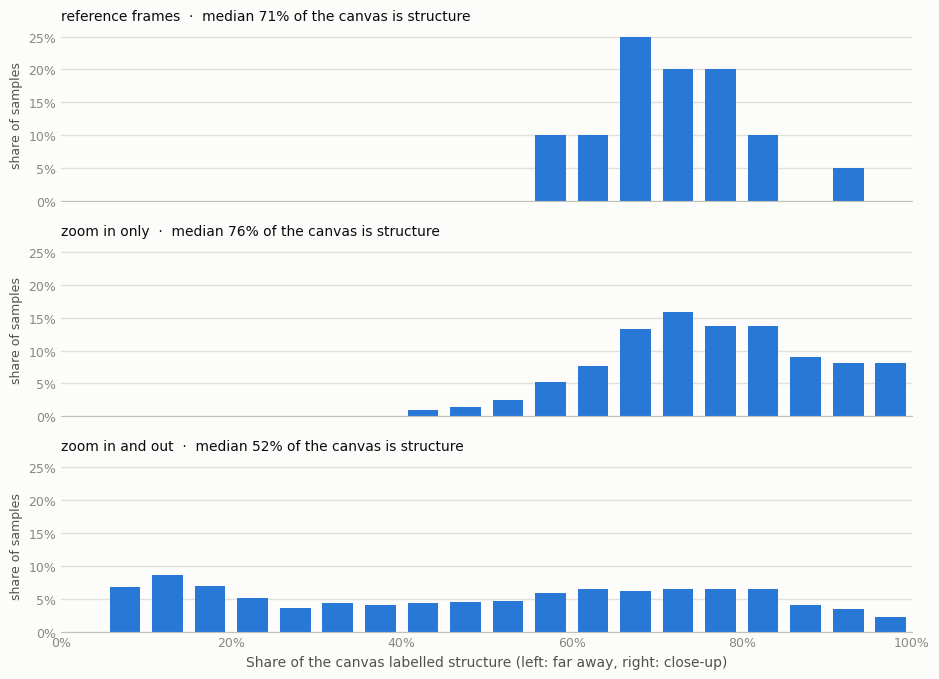

In [10]:
if labelled:
    variants = list(samples.variant.unique())
    edges = np.linspace(0, 1, 21)
    centres = (edges[:-1] + edges[1:]) / 2
    fig, axes = plt.subplots(len(variants), 1, figsize=(9.5, 2.3 * len(variants)), sharex=True, sharey=True,
                             facecolor=SURFACE)
    for ax, variant in zip(axes, variants):
        values = samples.loc[samples.variant == variant, "structure_share"]
        share = np.histogram(values, bins=edges)[0] / len(values)
        ax.bar(centres, share, width=0.036, color=BLUE, linewidth=0)
        ax.set_facecolor(SURFACE)
        ax.grid(axis="y", color=GRID, linewidth=1)
        ax.set_axisbelow(True)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color(AXIS)
        ax.tick_params(colors=MUTED, length=0, labelsize=9)
        ax.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
        ax.set_title(f"{variant}  ·  median {values.median():.0%} of the canvas is structure", loc="left",
                     fontsize=10, color=INK)
        ax.set_ylabel("share of samples", color=INK_SOFT, fontsize=9)
    axes[-1].set_xlabel("Share of the canvas labelled structure (left: far away, right: close-up)",
                        color=INK_SOFT, fontsize=10)
    axes[-1].xaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
    axes[-1].set_xlim(0, 1)
    fig.tight_layout()
    plt.show()